# 03 · Adding battery storage

In this tutorial the greenfield network of the previous tutorial is extended with a **battery** located at the same bus as the solar PV park (South). The battery is built from basic PyPSA components: a `Store`, which holds the energy, and two `Link`s, which charge and discharge it.

As in the previous tutorial, all capacities are *extendable*: the optimisation decides at the same time the cost-optimal capacities (now including the power and energy capacities of the battery) and the hourly dispatch. Compare every result with those of tutorial 02: Section 9 solves the same network without the battery and puts both side by side.

## 0. Import the required modules

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pypsa

pypsa.options.api.legacy_string_dtype = False  # keep pandas 3 string dtype (default from PyPSA 2.0); avoids a FutureWarning

## 1. Load the data

- `data.csv`: techno-economic parameters.
- `data_time_series.csv`: hourly capacity factors (`solar_CF`, `wind_CF`) and electricity demand (`demand_MW`).

In [2]:
### Load data.csv
params = pd.read_csv("data/data.csv", index_col="parameter")

# define a series with the values of the parameters for quick access
p = params["value"]

# show the parameters
params

,value,unit,description
parameter,,,
solar_p_nom,20.00,MW,Installed capacity of the solar PV park
solar_overnight_cost,600000.00,EUR/MW,Total (non-annualised) investment cost of sola...
solar_lifetime,25.00,years,Lifetime of solar PV
solar_marginal_cost,0.00,EUR/MWh,Operational cost of solar PV
wind_p_nom,20.00,MW,Installed capacity of the onshore wind park
wind_overnight_cost,1100000.00,EUR/MW,Total (non-annualised) investment cost of onsh...
wind_lifetime,25.00,years,Lifetime of onshore wind
wind_marginal_cost,5.00,EUR/MWh,Operational cost of onshore wind
ccgt_p_nom,50.00,MW,Installed capacity of the combined cycle gas t...


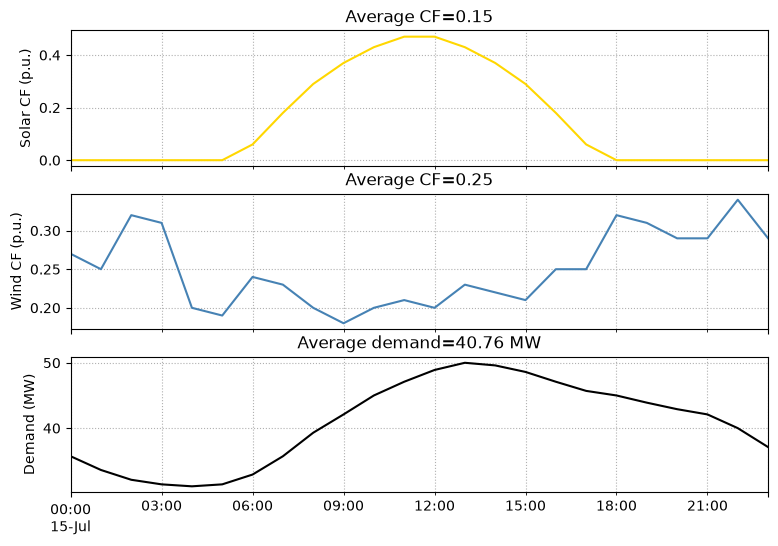

In [3]:
### Load data_time_series.csv
ts = pd.read_csv("data/data_time_series.csv", index_col="snapshot", parse_dates=True)

# Define a dict with the colors of each carrier (stored later in the network and used in all plots)
colors = {"solar": "gold",
          "wind": "steelblue",
          "gas": "indianred",
          "AC": "grey",
          "demand": "black",
          "battery": "darkviolet",
          "battery inverter": "violet"
}

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 6), sharex=True)

ts["solar_CF"].plot(ax=ax1, color=colors["solar"], ylabel="Solar CF (p.u.)", title=f"Average CF={ts["solar_CF"].mean():.2f}").grid(ls=":", which="both")
ts["wind_CF"].plot(ax=ax2, color=colors["wind"], ylabel="Wind CF (p.u.)", title=f"Average CF={ts["wind_CF"].mean():.2f}").grid(ls=":", which="both")
ts["demand_MW"].plot(ax=ax3, color=colors["demand"], ylabel="Demand (MW)", xlabel="", title=f"Average demand={ts["demand_MW"].mean():.2f} MW").grid(ls=":", which="both")

## 2. Create the network

No initial line capacity (`s_nom` = 0 by default), minimum capacity `s_nom_min=0` and `s_nom_extendable=True`.

In [4]:
n = pypsa.Network()

n.set_snapshots(ts.index)

n.add("Bus", ["North", "Center", "South"], x=[0, 0.2, 0], y=[2, 1, 0], v_nom=p["v_nom"])

n.add(
    "Line",
    ["North-Center", "South-Center"],
    bus0=["North", "South"],
    bus1=["Center", "Center"],
    x=p["line_x"],
    r=p["line_r"],
    s_nom_min=0,
    s_nom_extendable=True,
    length=p["line_length"],
    overnight_cost=p["line_overnight_cost"] * p["line_length"],
    lifetime=p["line_lifetime"],
    discount_rate=p["discount_rate"],
)

n.add("Carrier", list(colors), color=list(colors.values()))

## 3. Add generators

No initial capacity (`p_nom` = 0 by default), minimum capacity `p_nom_min=0` and `p_nom_extendable=True`.

In [5]:
### Solar PV park (South bus)
n.add(
    "Generator",
    "Solar_South",
    bus="South",
    carrier="solar",
    p_nom_min=0,
    p_nom_extendable=True,
    p_max_pu=ts["solar_CF"],
    overnight_cost=p["solar_overnight_cost"],
    lifetime=p["solar_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["solar_marginal_cost"],
)

### Wind farm (North bus)
n.add(
    "Generator",
    "Wind_North",
    bus="North",
    carrier="wind",
    p_nom_min=0,
    p_nom_extendable=True,
    p_max_pu=ts["wind_CF"],
    overnight_cost=p["wind_overnight_cost"],
    lifetime=p["wind_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["wind_marginal_cost"],
)

### Combined cycle gas turbine (Center bus)
# Dispatchable: without `p_max_pu`, it can produce up to `p_nom` in every hour.
n.add(
    "Generator",
    "CCGT_Center",
    bus="Center",
    carrier="gas",
    p_nom_min=0,
    p_nom_extendable=True,
    overnight_cost=p["ccgt_overnight_cost"],
    lifetime=p["ccgt_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["ccgt_marginal_cost"],
)

## 4. Add electricity demand

Basic parameters:

- `p_set`: imposed electricity demand (MW) in each snapshot.

In [6]:
n.add("Load",
      "Demand_Center",
      bus="Center",
      carrier="demand",
      p_set=ts["demand_MW"]
)

## 5. Add a battery

PyPSA offers two ways to model a battery:

- a single `StorageUnit`, whose energy capacity is tied to its power capacity by a fixed ratio (`max_hours`);
- a combination of basic components, so that the power capacity (MW) and the energy capacity (MWh) are optimised **independently**. This is the approach used here (and in PyPSA-Eur):

![Battery model: South bus, charger and discharger links, auxiliary DC bus and store](figures/battery_scheme.svg)

- **Bus** `South_battery` (carrier `battery`): an auxiliary bus representing the DC side of the battery.
- **Store** `Battery_South`: holds the energy. Its energy capacity `e_nom` (MWh) is extendable, with investment cost `battery_storage_overnight_cost` (EUR/MWh). With `e_cyclic=True` the state of charge at the end of the day equals that at the beginning: the battery cannot deliver energy it has not stored first.
- **Links** `Battery_South_charger` (South → South_battery) and `Battery_South_discharger` (South_battery → South): a `Link` transfers power from `bus0` to `bus1` with an `efficiency`, $p_1 = -\eta \, p_0$. Each link has efficiency $\sqrt{0.96} \approx 0.98$, so that a full charge-discharge cycle has the round-trip efficiency of the inverter given in the data (0.96). Both links have the carrier `battery inverter`.

Both links represent the **same physical inverter**. Its investment cost is therefore assigned only to the charger, and the capacities of the two links are related by an additional constraint (Section 6).

Note that the inverter (10 years) and the storage (25 years) have different lifetimes, so their annuities are different.

In [7]:
### Auxiliary bus for the battery (DC side)
n.add("Bus", "South_battery", carrier="battery", x=0.1, y=0)

### Energy storage (MWh)
n.add(
    "Store",
    "Battery_South",
    bus="South_battery",
    carrier="battery",
    e_nom_min=0,
    e_nom_extendable=True,
    e_cyclic=True,
    overnight_cost=p["battery_storage_overnight_cost"],
    lifetime=p["battery_storage_lifetime"],
    discount_rate=p["discount_rate"],
)

### Inverter (MW): one link for each direction, each with half of the round-trip losses
eta = p["battery_inverter_efficiency"] ** 0.5

n.add(
    "Link",
    "Battery_South_charger",
    bus0="South",
    bus1="South_battery",
    carrier="battery inverter",
    efficiency=eta,
    p_nom_min=0,
    p_nom_extendable=True,
    overnight_cost=p["battery_inverter_overnight_cost"],
    lifetime=p["battery_inverter_lifetime"],
    discount_rate=p["discount_rate"],
)

# Same physical inverter as the charger: its investment cost is already included there
n.add(
    "Link",
    "Battery_South_discharger",
    bus0="South_battery",
    bus1="South",
    carrier="battery inverter",
    efficiency=eta,
    p_nom_min=0,
    p_nom_extendable=True,
)

## 6. Optimisation

Minimises total system cost subject to the power balance at each bus and hour, the generator limits, the line capacities and the battery limits (power, energy and state of charge).

The charger and the discharger are the same device, so their capacities cannot be chosen independently: the power that the battery can absorb from the South bus must equal the power that it can inject into it. The `p_nom` of a link refers to its input (`bus0`), so the constraint is

$$p^{nom}_{charger} = \eta \cdot p^{nom}_{discharger}$$

PyPSA has no attribute for this, so it is added to the optimisation problem with `extra_functionality`: a function that PyPSA calls after building the model and before solving it. The model, `n.model`, is a [linopy](https://linopy.readthedocs.io) model, the optimisation library on which PyPSA is built. The capacity variables of the extendable links are stored in `n.model["Link-p_nom"]`.

In [8]:
def battery_inverter_constraint(n, snapshots):
    """Charging capacity = discharging capacity, both measured at the South bus."""
    p_nom = n.model["Link-p_nom"]
    charger = p_nom.sel(name="Battery_South_charger", drop=True)
    discharger = p_nom.sel(name="Battery_South_discharger", drop=True)
    eta_discharger = n.links.at["Battery_South_discharger", "efficiency"]
    n.model.add_constraints(charger - eta_discharger * discharger == 0, name="Link-battery_inverter")


# io_api="direct" passes the model to HiGHS in memory; the default LP file fails silently with decimal-comma locales
n.optimize(solver_name="highs", io_api="direct", extra_functionality=battery_inverter_constraint)

/tmp/ipykernel_53465/2914444785.py:11: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", io_api="direct", extra_functionality=battery_inverter_constraint)


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 224 primals, 513 duals
Objective: 4.82e+04
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-ext-p-lower, Link-ext-p-upper, Store-ext-e-lower, Store-ext-e-upper, Store-energy_balance were not assigned to the network.


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP has 513 rows; 224 cols; 982 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [5e+00, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [3e+01, 5e+01]
Presolving model
324 rows, 187 cols, 756 nonzeros 0s
252 rows, 139 cols, 660 nonzeros 0s
Dependent equations search running on 48 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
252 rows, 139 cols, 660 nonzeros 0s
Presolve reductions: rows 252(-261); columns 139(-85); nonzeros 660(-322) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 43(1847.4) 0.0s
        123     4.8249530047e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model status        

('ok', 'optimal')

## 7. Results

### Summary by technology

The battery is included through its components. Results are grouped by **name** instead of by carrier: grouping by carrier would add up the capacities of the charger and the discharger, which are the same physical inverter.

- **Optimal Capacity**: MW for generators and links, MWh for the store. The discharger capacity is slightly larger than the charger capacity because the `p_nom` of a link refers to its input (`bus0`), which for the discharger is the DC side (constraint of Section 6).
- **Supply / Withdrawal** (MWh): for a link, measured at its input (`bus0`): the charger withdraws energy from the South bus and the discharger from the `South_battery` bus. For the store: energy discharged / charged.
- **Capacity Factor**: average use of the capacity. For the store, the average state of charge relative to its energy capacity.
- **Curtailment**: only meaningful for generators.

In [9]:
cols = ["Installed Capacity", "Optimal Capacity", "Supply", "Withdrawal", "Capacity Factor", "Curtailment"]
summary = n.statistics(components=["Generator", "Link", "Store"], groupby="name")[cols]
summary.loc["Link", "Curtailment"] = float("nan")  # for a Link, statistics reports the unused capacity, not curtailed energy
summary.round(2)

Installed Capacity  Optimal Capacity  \
Generator CCGT_Center                              0.0              0.00   
          Solar_South                              0.0             57.35   
          Wind_North                               0.0            129.00   
Link      Battery_South_charger                    0.0             10.01   
          Battery_South_discharger                 0.0             10.22   
Store     Battery_South                            0.0             38.00   

                                    Supply  Withdrawal  Capacity Factor  \
Generator CCGT_Center                 0.00        0.00             0.00   
          Solar_South               206.47        0.00             0.15   
          Wind_North                773.98        0.00             0.25   
Link      Battery_South_charger       0.00       53.79             0.22   
          Battery_South_discharger    0.00       52.71             0.21   
Store     Battery_South              52.71       52.71             0.43   

                                    Curtailment  
Generator CCGT_Center                       0.0  
          Solar_South                       0.0  
          Wind_North                        0.0  
Link      Battery_South_charger             NaN  
          Battery_South_discharger          NaN  
Store     Battery_South                     0.0

Additional battery details. The **duration** (energy-to-power ratio, in hours) is a result of the optimisation, not an input as in a `StorageUnit`. The energy charged and discharged is measured at the South bus (AC side), so their difference is the energy lost in the inverter.

In [10]:
charge = n.links_t.p0["Battery_South_charger"]         # MW withdrawn from the South bus
discharge = -n.links_t.p1["Battery_South_discharger"]   # MW injected into the South bus

power_MW = n.links.p_nom_opt["Battery_South_charger"]
energy_MWh = n.stores.e_nom_opt["Battery_South"]

pd.Series({
    "Duration (h)": energy_MWh / power_MW,
    "Energy charged from South (MWh)": charge.sum(),
    "Energy discharged to South (MWh)": discharge.sum(),
    "Losses (MWh)": charge.sum() - discharge.sum(),
    "Equivalent full cycles": discharge.sum() / energy_MWh,
}).round(2).to_frame("Battery")

,Battery
Duration (h),3.80
Energy charged from South (MWh),53.79
Energy discharged to South (MWh),51.64
Losses (MWh),2.15
Equivalent full cycles,1.36


### Hourly dispatch

Above zero: generation and battery discharging. Below zero: battery charging. In every hour, the positive area minus the charging equals the demand.

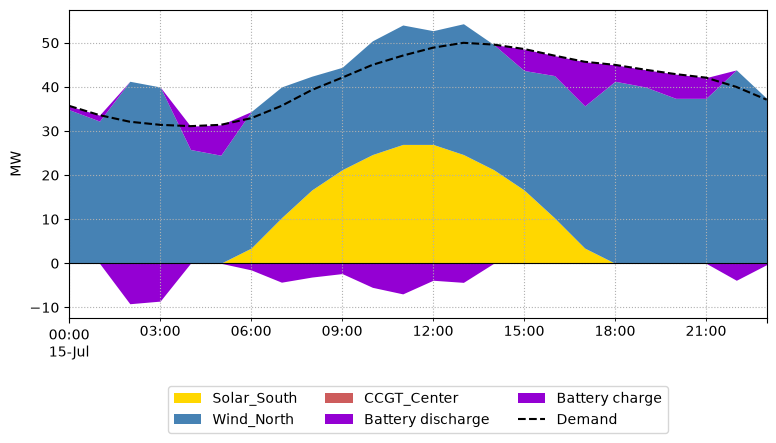

In [11]:
# Gather the dispatch of all generators and the battery (clip removes tiny solver round-offs with the wrong sign)
df_dispatch = pd.concat(
    [n.generators_t.p, discharge.clip(lower=0).rename("Battery discharge"), -charge.clip(lower=0).rename("Battery charge")], axis=1
)
dispatch_colors = list(n.generators.carrier.map(n.carriers.color)) + [n.carriers.color["battery"]] * 2

# Make a stacked area plot
ax = df_dispatch.plot.area(figsize=(9, 4), color=dispatch_colors, lw=0, ylabel="MW", xlabel="")
n.loads_t.p_set["Demand_Center"].plot(ax=ax, color=n.carriers.color["demand"], ls="--", label="Demand", xlabel="")
ax.axhline(0, color="black", lw=0.8)
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3);

### Battery state of charge

Energy stored in the battery at the end of each hour. The dashed line is the optimal energy capacity `e_nom_opt`. With `e_cyclic=True`, the state of charge at the end of the day equals that at the beginning.

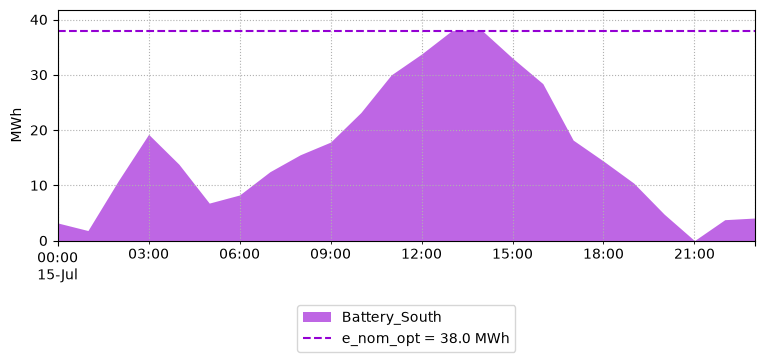

In [12]:
batt_color = n.carriers.color["battery"]
soc = n.stores_t.e["Battery_South"]

ax = soc.plot.area(figsize=(9, 3), color=batt_color, alpha=0.6, lw=0, ylabel="MWh", xlabel="")
ax.axhline(energy_MWh, color=batt_color, ls="--", lw=1.5, label=f"e_nom_opt = {energy_MWh:.1f} MWh")
ax.set_ylim(0, 1.1 * energy_MWh)
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=1);

Plot with the curtailment: renewable energy that is available (`p_max_pu · p_nom_opt`) but not used.

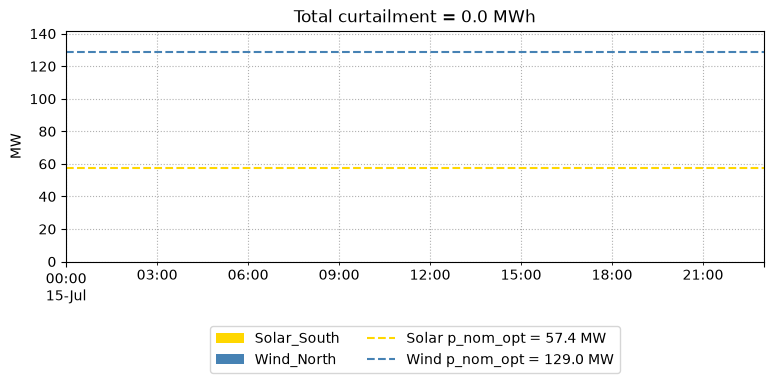

In [13]:
# Curtailment of renewables = available power - dispatched power
renewables = ["Solar_South", "Wind_North"]
p_nom_opt = n.generators.p_nom_opt
available = n.generators_t.p_max_pu[renewables] * p_nom_opt[renewables]
df_curtailment = (available - n.generators_t.p[renewables]).clip(lower=0)  # clip removes tiny negative solver round-offs

ax = df_curtailment.plot.area(figsize=(9, 3), color=n.generators.carrier[renewables].map(n.carriers.color), lw=0, ylabel="MW", xlabel="",
                              title=f"Total curtailment = {df_curtailment.sum().sum():.1f} MWh")
ax.axhline(p_nom_opt["Solar_South"], color=n.carriers.color["solar"], ls="--", lw=1.5, label=f"Solar p_nom_opt = {p_nom_opt['Solar_South']:.1f} MW")
ax.axhline(p_nom_opt["Wind_North"], color=n.carriers.color["wind"], ls="--", lw=1.5, label=f"Wind p_nom_opt = {p_nom_opt['Wind_North']:.1f} MW")
ax.set_ylim(0, 1.1 * p_nom_opt[renewables].max())
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2);

### Line flows

As in tutorial 02, lines work at full capacity in at least one hour. Compare their optimal capacities with those of tutorial 02: has the battery at the South bus changed the need for transmission?

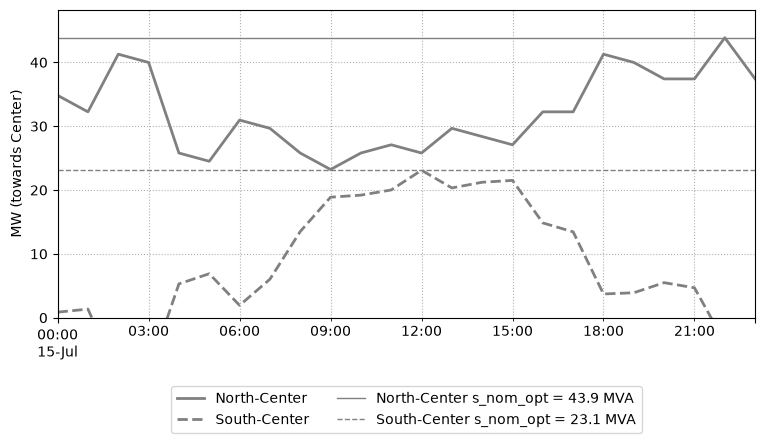

In [14]:
ac_color = n.carriers.color["AC"]
s_nom_opt = n.lines.s_nom_opt

ax = n.lines_t.p0[["North-Center", "South-Center"]].plot(figsize=(9, 4), color=ac_color, style=["-", "--"], lw=2, ylabel="MW (towards Center)", xlabel="")
ax.axhline(s_nom_opt["North-Center"], color=ac_color, ls="-", lw=1, label=f"North-Center s_nom_opt = {s_nom_opt['North-Center']:.1f} MVA")
ax.axhline(s_nom_opt["South-Center"], color=ac_color, ls="--", lw=1, label=f"South-Center s_nom_opt = {s_nom_opt['South-Center']:.1f} MVA")
ax.set_ylim(0, 1.1 * s_nom_opt.max())
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2);

### Nodal prices (EUR/MWh)

Dual variable of the power balance at each bus. Compare with tutorial 02, where prices alternated between 5 EUR/MWh (wind marginal), 80 EUR/MWh (CCGT marginal) and a scarcity peak at 17:00. Which technology sets the price in each hour now?

The auxiliary bus `South_battery` also has a price: the *value of the stored energy*. It is not plotted here, but it is used in the economic analysis (Section 8).

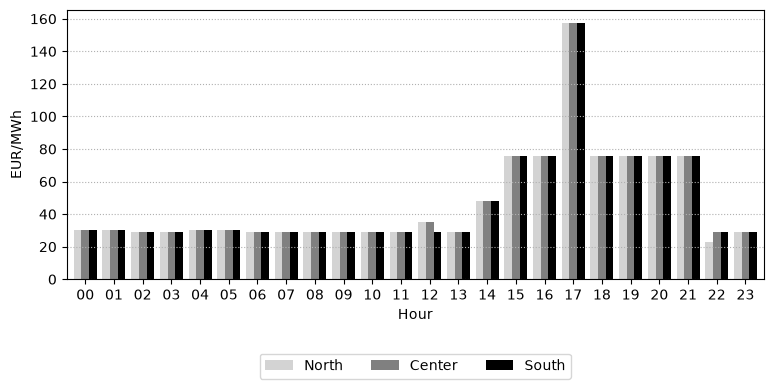

In [15]:
prices = n.buses_t.marginal_price

# Grouped bars per hour, one shade of grey per bus
ax = prices.set_axis(prices.index.strftime("%H"))[["North", "Center", "South"]].plot.bar(
    figsize=(9, 3.5), width=0.8, color=["lightgrey", "grey", "black"], ylabel="EUR/MWh", xlabel="Hour", rot=0
)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3);

### Cost analysis

Costs by carrier over the 24 modelled hours (EUR); lines are grouped under their carrier `AC`, and the two battery links under `battery inverter`:

- **CAPEX**: investment annuity (from `overnight_cost`, `lifetime` and `discount_rate`) scaled to 24 h.
- **OPEX**: `marginal_cost` × dispatched energy.

In this example, lines and the battery only have CAPEX (no marginal cost). Technologies with zero optimal capacity have no costs and do not appear.

In [16]:
components = ["Generator", "Line", "Link", "Store"]
cols = ["Capital Expenditure", "Operational Expenditure"]
n.statistics(components=components)[cols].round(2)

Capital Expenditure  Operational Expenditure
Generator gas                              0.00                      0.0
          solar                         8090.17                      0.0
          wind                         33359.43                   3869.9
Line      AC                             412.81                      0.0
Link      battery inverter               819.95                      0.0
Store     battery                       1697.27                      0.0

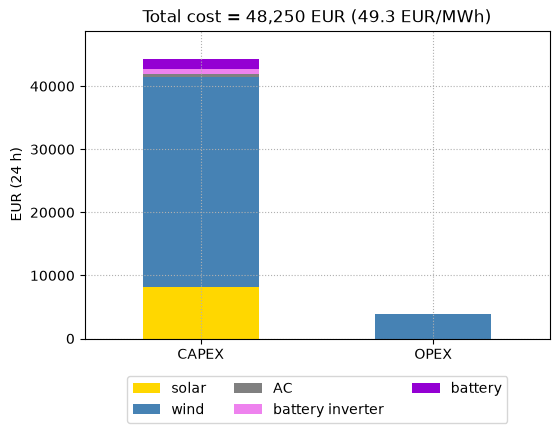

In [17]:
costs = pd.concat(
    {"CAPEX": n.statistics.capex(components=components), "OPEX": n.statistics.opex(components=components)}, axis=1
).droplevel("component").fillna(0)

# Total cost and cost per MWh of demand
total_cost = costs.values.sum()
demand_MWh = n.loads_t.p_set.sum().sum()

ax = costs.T.plot.bar(stacked=True, figsize=(6, 4), color=costs.index.map(n.carriers.color), ylabel="EUR (24 h)", xlabel="", rot=0,
                      title=f"Total cost = {total_cost:,.0f} EUR ({total_cost / demand_MWh:.1f} EUR/MWh)")
ax.set_ylim(top=1.1 * costs.sum().max())
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.grid(ls=":", which="both")


## 8. Economic analysis

### Battery revenue: energy arbitrage

The battery does not produce energy: it buys energy when it is cheap (charging) and sells it when it is expensive (discharging). Its income is the **arbitrage** revenue at the South bus,

$$\sum_t \lambda_{South,t} \cdot (p^{discharge}_t - p^{charge}_t),$$

where $\lambda_{South,t}$ is the price at the South bus. As for any other asset with optimal capacity, this income recovers exactly the battery investment cost (inverter + storage) for the modelled day (see the check below).

In [18]:
# Check: the arbitrage income of the battery equals its investment cost for the modelled day
prices = n.buses_t.marginal_price
arbitrage = (prices["South"] * (discharge - charge)).sum()
battery_capex = costs.loc[["battery inverter", "battery"], "CAPEX"].sum()

print(f"Battery income from arbitrage, 24 h:     {arbitrage:,.0f} EUR")
print(f"Battery CAPEX (inverter + storage), 24 h: {battery_capex:,.0f} EUR")

Battery income from arbitrage, 24 h:     2,517 EUR
Battery CAPEX (inverter + storage), 24 h: 2,517 EUR


### Revenue and market value

Same definitions as in tutorial 02:

- **Revenue** (EUR): income from selling energy at the nodal price, $\sum_t \lambda_{b,t} \cdot p_t$. For a line it is the *congestion rent*. For the demand it is negative: it is what consumers pay.
- **Market value** (EUR/MWh): revenue divided by the energy produced (or transported, for lines).
- **Profit** (EUR): revenue − CAPEX − OPEX.

The battery appears split into its two parts, connected through the `South_battery` bus: the `battery inverter`, whose income is the price difference between the South and South_battery buses, and the `battery` storage, which buys and sells at the price of the South_battery bus (the value of the stored energy) at different hours. Their revenues add up to the arbitrage income above, and each part recovers exactly its own costs (zero profit).

In [19]:
components = ["Generator", "Line", "Link", "Store", "Load"]
revenue = n.statistics.revenue(components=components, drop_zero=False).droplevel("component")
market_value = n.statistics.market_value(components=components).droplevel("component")

# The demand has no CAPEX or OPEX, so its profit is not defined (NaN)
economics = costs.reindex(revenue.index).fillna({"CAPEX": 0, "OPEX": 0}).assign(
    Revenue=revenue,
    Profit=lambda df: (df["Revenue"] - df["CAPEX"] - df["OPEX"]).round(1) + 0,  # "+ 0" turns -0.0 into 0.0
    **{"Market value (EUR/MWh)": market_value},
)
economics.loc["demand", ["CAPEX", "OPEX", "Profit"]] = float("nan")
economics.round(1)

,CAPEX,OPEX,Revenue,Profit,Market value (EUR/MWh)
carrier,,,,,
gas,0.0,0.0,0.0,0.0,NaN
solar,8090.2,0.0,8090.2,0.0,39.2
wind,33359.4,3869.9,37229.3,0.0,48.1
AC,412.8,0.0,412.8,0.0,0.4
battery inverter,819.9,0.0,819.9,0.0,7.7
battery,1697.3,0.0,1697.3,0.0,4.4
demand,NaN,NaN,-48249.5,NaN,-49.3


Balance between system cost and what consumers pay, by carrier: **Paid by consumers = System cost + Profit**. In equilibrium both bars are equal and there is no profit.

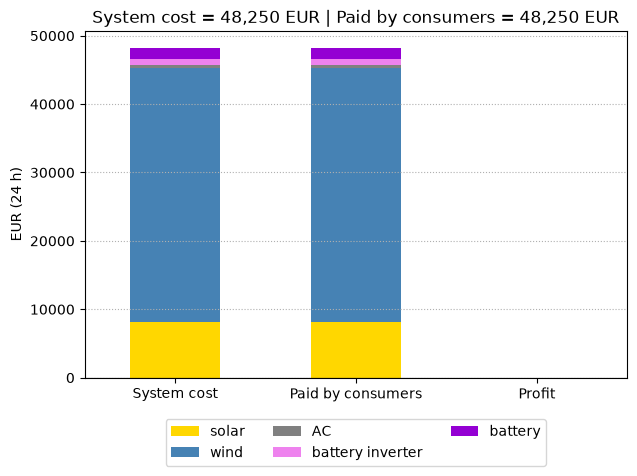

In [20]:
system_cost = costs.sum(axis=1)                                      # CAPEX + OPEX of each carrier
paid = economics.drop("demand")["Revenue"].reindex(system_cost.index)  # what consumers pay to each carrier
balance = pd.DataFrame({"System cost": system_cost, "Paid by consumers": paid, "Profit": paid - system_cost}).T

ax = balance.plot.bar(stacked=True, figsize=(7, 4.5), color=balance.columns.map(n.carriers.color), ylabel="EUR (24 h)", xlabel="", rot=0,
                      title=f"System cost = {system_cost.sum():,.0f} EUR | Paid by consumers = {paid.sum():,.0f} EUR")
ax.axhline(0, color="black", lw=0.8)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3);

## 9. Comparison with tutorial 02

To compare both systems, the battery is removed from a copy of the network, which is then optimised again: this reproduces the results of tutorial 02.

In [21]:
n.model.solver_model = None  # a solved network can only be copied after detaching the solver
n_02 = n.copy()
n_02.remove("Link", ["Battery_South_charger", "Battery_South_discharger"])
n_02.remove("Store", "Battery_South")
n_02.remove("Bus", "South_battery")

n_02.optimize(solver_name="highs", io_api="direct", log_to_console=False)

/tmp/ipykernel_53465/2128844257.py:7: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n_02.optimize(solver_name="highs", io_api="direct", log_to_console=False)


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.model:Solver options:
 - log_to_console: False


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 125 primals, 317 duals
Objective: 5.11e+04
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper were not assigned to the network.


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


('ok', 'optimal')

In [22]:
def summary(n):
    """Main results of a solved network."""
    renewables = ["Solar_South", "Wind_North"]
    available = n.generators_t.p_max_pu[renewables] * n.generators.p_nom_opt[renewables]
    demand = n.loads_t.p_set["Demand_Center"]
    has_battery = "Battery_South" in n.stores.index
    return pd.Series({
        "Solar capacity (MW)": n.generators.p_nom_opt["Solar_South"],
        "Wind capacity (MW)": n.generators.p_nom_opt["Wind_North"],
        "CCGT capacity (MW)": n.generators.p_nom_opt["CCGT_Center"],
        "Battery power (MW)": n.links.p_nom_opt["Battery_South_charger"] if has_battery else 0,
        "Battery energy (MWh)": n.stores.e_nom_opt["Battery_South"] if has_battery else 0,
        "Line North-Center (MVA)": n.lines.s_nom_opt["North-Center"],
        "Line South-Center (MVA)": n.lines.s_nom_opt["South-Center"],
        "Curtailment (MWh)": (available - n.generators_t.p[renewables]).clip(lower=0).sum().sum(),
        "Total cost (EUR)": n.statistics.capex().sum() + n.statistics.opex().sum(),
        "Cost per MWh of demand (EUR/MWh)": (n.statistics.capex().sum() + n.statistics.opex().sum()) / demand.sum(),
        "Max. price at Center (EUR/MWh)": n.buses_t.marginal_price["Center"].max(),
        "Min. price at Center (EUR/MWh)": n.buses_t.marginal_price["Center"].min(),
    })


comparison = pd.DataFrame({"Tutorial 02 (no battery)": summary(n_02), "Tutorial 03 (battery)": summary(n)})
comparison["Difference"] = comparison["Tutorial 03 (battery)"] - comparison["Tutorial 02 (no battery)"]
comparison.round(2)

,Tutorial 02 (no battery),Tutorial 03 (battery),Difference
Solar capacity (MW),44.20,57.35,13.15
Wind capacity (MW),140.62,129.00,-11.63
CCGT capacity (MW),7.89,0.00,-7.89
Battery power (MW),0.00,10.01,10.01
Battery energy (MWh),0.00,38.00,38.00
Line North-Center (MVA),45.00,43.86,-1.14
Line South-Center (MVA),20.78,23.10,2.33
Curtailment (MWh),56.85,0.00,-56.85
Total cost (EUR),51091.40,48249.53,-2841.87
Cost per MWh of demand (EUR/MWh),52.22,49.32,-2.90


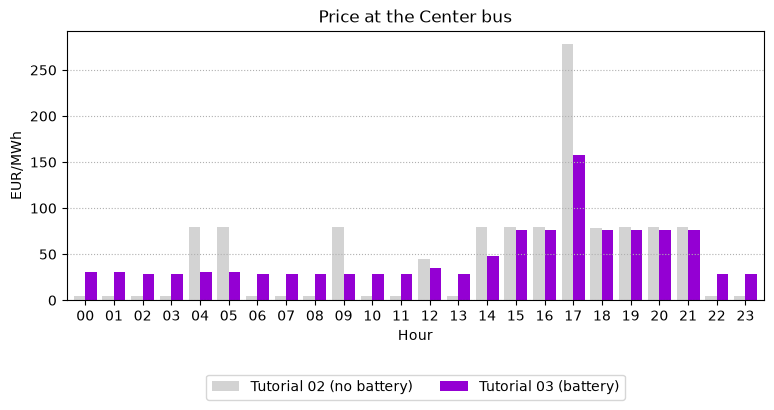

In [23]:
# Price at the Center bus (where the demand is) with and without battery
price_comparison = pd.DataFrame({
    "Tutorial 02 (no battery)": n_02.buses_t.marginal_price["Center"],
    "Tutorial 03 (battery)": n.buses_t.marginal_price["Center"],
})

ax = price_comparison.set_axis(price_comparison.index.strftime("%H")).plot.bar(
    figsize=(9, 3.5), width=0.8, color=["lightgrey", n.carriers.color["battery"]], ylabel="EUR/MWh", xlabel="Hour", rot=0,
    title="Price at the Center bus"
)
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2);

## 10. Final remarks

Reflect on the differences with respect to tutorial 02:

- What happens to the CCGT? Which asset now covers the demand at the evening peak, and who sets the price at 17:00?
- Why does the optimal solar capacity increase while the wind capacity decreases? What does the battery do with the solar energy produced at midday?
- How do the curtailment and the prices change? Why is the price range (max − min) much narrower than in tutorial 02?
- How does the battery duration (MWh/MW) compare with that of typical commercial batteries (2–4 h)? Change `battery_storage_overnight_cost` or `battery_inverter_overnight_cost` in `data.csv` and observe how the duration changes.
- The battery is placed at the South bus. Does it reduce the capacity needed for the South-Center line? Move it to the Center or North bus and compare the total cost.
- Only one day is modelled and the battery must end the day with the same state of charge as it started (`e_cyclic=True`). Would it be safe to dismantle all gas capacity based on this result? Think of several consecutive days with little sun and wind.